**( Machine Learning )**

# ***" Programming Assignment 1 "***

**Preparing to Model (Chapter 2)**

---
---

### **1. Import Libraries :**

In this step, we import **the Python libraries** needed for data analysis and visualization. **Pandas** is used to handle the dataset, **NumPy** supports numerical operations, **Matplotlib** and **Seaborn** are used to create plots.

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **2. Load the Dataset :**

In this step, we load **the Vehicle Fuel dataset** using **Pandas**. We display the dataset's shape to know the number of rows and columns, and show the first five rows to understand the structure of the data. The missing values represented by **?** are treated as **NaN**.

In [ ]:
# Load Vehicle Fuel dataset
df = pd.read_csv('vehicle_fuel Dataset.csv', na_values=["?"])

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Dataset shape: (320, 9)

First 5 rows:


,fuel_eff,cylinders,engine_size,horsepower,weight,acceleration,model_year,origin,car_name
0,8.3,8,6000,284.0,1739,16.7,2011,1,ford explorer
1,18.6,4,1740,94.0,1055,18.7,2019,2,bmw 520i
2,12.5,6,2800,141.0,1370,18.6,2021,1,buick lacrosse
3,10.3,8,4430,203.0,1635,19.2,2015,1,dodge dart
4,15.7,6,2790,129.0,1183,15.4,2021,1,chevrolet tahoe


### **3. Check Data Types and Data Quality :**

The data dictionary describes the data type of each attribute. However, the actual dataset may contain unexpected data types or missing values. Therefore, we check the data types and missing values before performing the analysis.

In [ ]:
# Check data types
print("Data types of each column:")
display(df.dtypes)

# Check missing values
print("Missing values in each column:")
display(df.isnull().sum())

Data types of each column:


,0
fuel_eff,float64
cylinders,int64
engine_size,int64
horsepower,float64
weight,int64
acceleration,float64
model_year,int64
origin,int64
car_name,object


Missing values in each column:


,0
fuel_eff,0
cylinders,0
engine_size,0
horsepower,7
weight,0
acceleration,0
model_year,0
origin,0
car_name,0




---

---

---


# ***Question 1 _ Central Tendency***

## **(a) Calculate Mean, Median, and Deviation :**

The mean and median are calculated for every numeric attribute in the dataset, except the non-numeric "car_name" column.

**The percentage deviation** is calculated as :
---
**|mean - median| / mean x 100**
---

A deviation **greater than 10%** is classified as **High**, while a deviation of **10% or less** is classified as **Low**.

***" The missing values are ignored when calculating the mean and median. "***

In [ ]:
# Calculate mean, median and deviation
numeric_df = df.select_dtypes(include=np.number)

results = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median()
})

results["Deviation"] = (
    abs(results["Mean"] - results["Median"])
    / results["Mean"] * 100
)

results["Verdict"] = np.where(
    results["Deviation"] > 10,
    "High", "Low"
)

display(results.round(3))

,Mean,Median,Deviation,Verdict
fuel_eff,13.394,14.0,4.526,Low
cylinders,5.344,4.0,25.146,High
engine_size,2985.531,2320.0,22.292,High
horsepower,150.070,121.0,19.371,High
weight,1333.097,1238.0,7.134,Low
acceleration,17.518,17.6,0.466,Low
model_year,2016.072,2016.0,0.004,Low
origin,1.628,1.0,38.580,High


**The previous table compares the mean and median for every numeric attribute. The attributes classified as High require further investigation. However, The high deviation alone does not prove that the data contains errors.**

When the mean is greater than the median, the distribution may be right-skewed because relatively large values can pull the mean upward. This possibility should be checked using the data distribution and box plots.

On the other hand, When the mean is smaller than the median, the distribution may be left-skewed because relatively small values can pull the mean downward.

***" This possibility should be checked using the data distribution and box plots. "***

## **(b) Identify the attributes that need further investigation :**

The attributes classified as **High** in the previous table are expected to be:

- **cylinders**
- **engine_size**
- **horsepower**
- **origin**

The high deviation indicates that the mean and median differ noticeably. This may be caused by the way values are distributed across categories.

For **engine_size** and **horsepower**, larger values may correspond to vehicles with larger or more powerful engines. These values should be investigated using the box plots and other vehicle attributes before deciding whether they are errors.

***" A high deviation is a signal for further investigation, not proof that a value is incorrect. "***

## **(c) Investigate the missing values :**

In [ ]:
print("The number of the missing horsepower records:", df["horsepower"].isnull().sum())

print(
    "The number of the vailable numeric horsepower records:",
    df["horsepower"].notnull().sum()
)

print("The Horsepower mean:", round(df["horsepower"].mean(), 3))
print("The Horsepower median:", round(df["horsepower"].median(), 3))

The number of the missing horsepower records: 7
The number of the vailable numeric horsepower records: 313
The Horsepower mean: 150.07
The Horsepower median: 121.0


The **horsepower** column contains **7 records** marked with **?** instead of a numeric value.

These entries are treated as missing values **NaN** when the CSV file is loaded. **Pandas** calculates the mean and median using the available numeric values in the column.

***" No rows are deleted, no missing horsepower values are replaced, and the original CSV file is not modified. "***

## **(d) Explain the high deviation of the discrete attributes :**

The two attributes that have high deviation are **cylinders** and **origin**.

- **cylinders :** This attribute represents a discrete count of engine cylinders and has only a few possible values.
- **origin :** This attribute uses the codes 1, 2, and 3 to represent North America, Europe, and Asia.

Their high deviations may be related to the frequency distribution of these discrete values rather than recording errors.

In particular, **origin** is a categorical code. The numerical difference between origin codes does not represent a meaningful physical difference. Therefore, its mean and deviation should be determined carefully.


---

---

---


# ***Question 2 _ Box Plots and Outliers***

In this section, we use Tukey box plots to visualize the distribution of **acceleration**, **engine_size** and **origin**, and identify the outliers. The whiskers extend to the furthest data values within **1.5 x IQR** of the box.

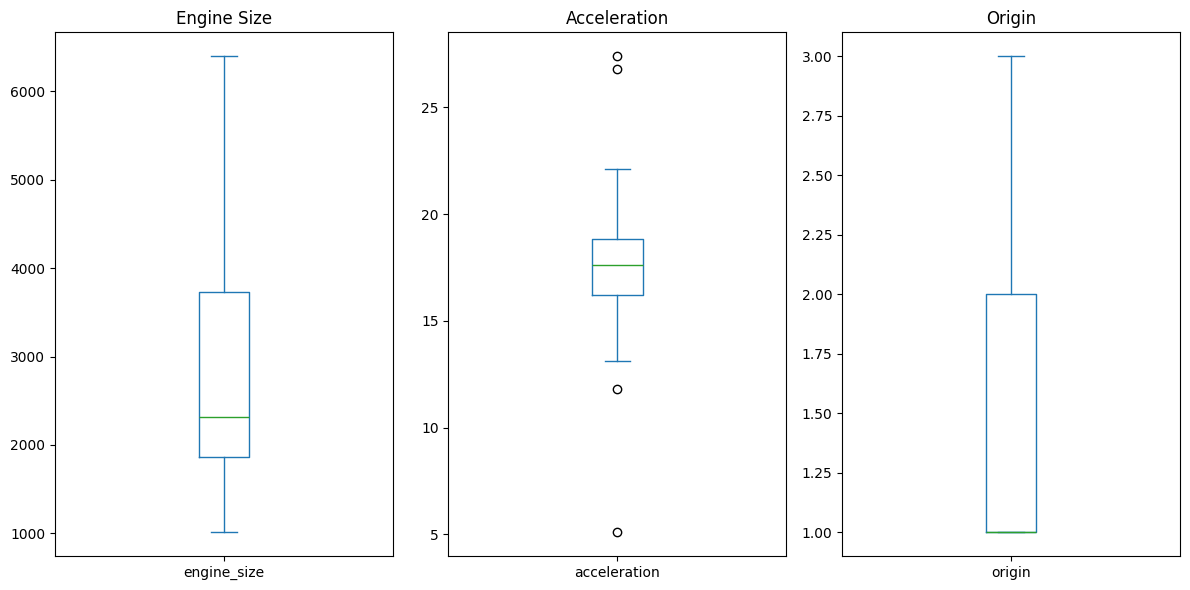

In [ ]:

# Create Tukey box plots for the required attributes
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
df["engine_size"].plot(kind="box")
plt.title("Engine Size")

plt.subplot(1, 3, 2)
df["acceleration"].plot(kind="box")
plt.title("Acceleration")

plt.subplot(1, 3, 3)
df["origin"].plot(kind="box")
plt.title("Origin")

plt.tight_layout()
plt.show()


**The box plots** provide a visual summary of the three attributes. They help us examine the median, quartiles, whisker lengths, and the outliers. Each attribute will be analyzed separately in the following sections.

## ***Part A _ Acceleration :***

### **(a) Check Acceleration Outliers :**

**The box plot** is used to identify possible outliers in the **acceleration** attribute. According to Tukey's rule, values below **(lower bound) = Q1 - 1.5 x IQR** or above **(upper bound) = Q3 + 1.5 x IQR** are considered outliers.

In [ ]:
# check acceleration outliers

col = "acceleration"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

below_outliers = (df[col] < lower_bound).sum()
above_outliers = (df[col] > upper_bound).sum()

print("The Lower bound:", lower_bound)
print("The Upper bound:", upper_bound)
print("The Outliers below the lower bound:", below_outliers)
print("The Outliers above the upper bound:", above_outliers)
print("The Total number of outliers:", below_outliers + above_outliers)

The Lower bound: 12.2625
The Upper bound: 22.7625
The Outliers below the lower bound: 2
The Outliers above the upper bound: 2
The Total number of outliers: 4


The box plot shows **outliers**. There are **2** outliers below the lower bound and **2** outliers above the upper bound, giving a total of **4** outliers.

### **(b) Identifying Acceleration Outliers :**

The following code identifies the vehicles behind these outliers. Their names and other attributes can help us investigate whether the values are natural or a likely recording errors.

In [ ]:
# Identify acceleration outliers and inspect their attributes

acceleration_outliers = df.loc[
    (df["acceleration"] < lower_bound) |
    (df["acceleration"] > upper_bound),
    [
        "fuel_eff", "cylinders", "engine_size",
        "horsepower", "weight", "acceleration",
        "model_year", "origin", "car_name"
    ]
].sort_values("acceleration")

display(acceleration_outliers)

,fuel_eff,cylinders,engine_size,horsepower,weight,acceleration,model_year,origin,car_name
110,8.9,8,6200,450.0,1780,5.1,2015,1,chevrolet corvette
14,6.5,8,6210,278.0,1852,11.8,2015,1,dodge charger
203,18.9,4,1420,75.0,1080,26.8,2020,2,volkswagen polo tdi
45,19.5,4,1460,65.0,1000,27.4,2017,3,nissan micra diesel


The analysis identified **4 acceleration outliers**.

*  **Chevrolet Corvette:** It has **450 horsepower** and **6200 engine size**. Its low acceleration value **may be reasonable**.

* **Dodge Charger:** It has **278 horsepower** and **6210 engine size**. Its low acceleration value **may also be reasonable*8.

* **Nissan Micra Diesel:** It has **65 horsepower** and **1460 engine size**. Its high acceleration value **may be reasonable**.

* **Volkswagen Polo TDI:** It has **75 horsepower** and **1420 engine size**. Its high acceleration value **may also be reasonable**.

**Based on the available attributes, these outliers appear to be natural rather than clear recording errors. Therefore, their values should not be amended without further evidence that they are incorrect.**

### **(c) Mean VS Median :**

**Acceleration** had one of the smallest deviations **(in Question 1)**, but it still contains **4 outliers**.

This is because mean and median describe the center of the data, while outliers are values far from the main distribution.

Therefore, a small difference between the mean and median does not guarantee that there are no outliers. The mean can be affected by extreme values, while the median is less affected by them.

**This shows that we should not rely only on the mean and median to detect outliers. We should also use box plots and examine the data when investigating outliers.**



---



## ***Part B _ Engine_size :***

### **(a) Check Engine_size Outliers :**

**The box plot** is used to identify possible outliers in the **engine_size** attribute. According to Tukey's rule, values below **(lower bound) = Q1 - 1.5 x IQR** or above **(upper bound) = Q3 + 1.5 x IQR** are considered outliers.

In [ ]:
# Check Engine_size Outliers
col = "engine_size"

Q1 = df[col].quantile(0.25)
Q2 = df[col].quantile(0.50)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

min = df[col].min()
max = df[col].max()

lower_whisker = abs(Q1 - min)
upper_whisker = abs(max - Q3)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

below_outliers = (df[col] < lower_bound).sum()
above_outliers = (df[col] > upper_bound).sum()

print("Q1:",Q1)
print("Q2:",Q2)
print("Q3:",Q3)
print("The Lower whisker:", lower_whisker)
print("The Upper whisker:", upper_whisker)
print("The Lower bound:", lower_bound)
print("The Upper bound:", upper_bound)
print("The Outliers below the lower bound:", below_outliers)
print("The Outliers above the upper bound:", above_outliers)
print("The Total number of outliers:", below_outliers + above_outliers)

Q1: 1857.5
Q2: 2320.0
Q3: 3730.0
The Lower whisker: 847.5
The Upper whisker: 2670.0
The Lower bound: -951.25
The Upper bound: 6538.75
The Outliers below the lower bound: 0
The Outliers above the upper bound: 0
The Total number of outliers: 0


The analysis shows **no outliers**; As **all engine_size values** fall within the lower and upper bounds.

The median is **closer** to **Q1** than to **Q3**.

The **upper** whisker is **longer than** the **lower** whisker, indicating a **greater spread** toward **higher engine_size values**.

### **(b) Calculate whisker lengths as a percantage :**

In [ ]:
# Calculate whisker lengths as percentages
max_whisker_length = 1.5 * IQR

lower_whisker_percentage = (lower_whisker / max_whisker_length) * 100
upper_whisker_percentage = (upper_whisker / max_whisker_length) * 100

print("The Maximum allowable whisker length:", max_whisker_length)
print("The Lower whisker percentage:", round(lower_whisker_percentage, 3), "%")
print("The Upper whisker percentage:", round(upper_whisker_percentage, 3), "%")

The Maximum allowable whisker length: 2808.75
The Lower whisker percentage: 30.174 %
The Upper whisker percentage: 95.06 %


**The maximum allowable whisker length** is **1.5 ء IQR = 2808.75**.

- **Lower whisker length** = **Q1 - minimum** = 1857.5 - 1010 = **847.5**.

  **Percentage** = (847.5 / 2808.75) x 100 = **30.174 %**.

- **Upper whisker length** = **maximum - Q3** = 6400 - 3730 = **2670**.

  **Percentage** = (2670 / 2808.75) x 100 = **95.06 %**.

### **(c) Engine Size Analysis :**

**(In Question 1)**, **engine_size** was classified as **"High"** ; As **the mean is greater than the median**, indicating **a possible right-skewed distribution**. However, the box plot shows **no outliers**.

**The upper whisker** is much **longer** than **the lower whisker**.

**The median** is **closer to Q1 than to Q3**. This suggests that the distribution has a greater spread toward **higher engine_size values**.

**Therefore, the "High" result may be explained by the shape and spread of the distribution rather than by outliers.**


---


## ***Part C _ Origin :***

### **(a) Check Origin Outliers :**

**The box plot** is used to identify possible outliers in the **Origin** attribute. According to Tukey's rule, values below **(lower bound) = Q1 - 1.5 x IQR** or above **(upper bound) = Q3 + 1.5 x IQR** are considered outliers.

In [ ]:
# Check origin Outliers
col = "origin"

Q1 = df[col].quantile(0.25)
Q2 = df[col].quantile(0.50)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1

min = df[col].min()
max = df[col].max()

lower_whisker = abs(Q1 - min)
upper_whisker = abs(max - Q3)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

below_outliers = (df[col] < lower_bound).sum()
above_outliers = (df[col] > upper_bound).sum()

print("Q1:",Q1)
print("Q2:",Q2)
print("Q3:",Q3)
print("min:",min)
print("max:",max)
print("The Lower whisker:", lower_whisker)
print("The Upper whisker:", upper_whisker)
print("The Lower bound:", lower_bound)
print("The Upper bound:", upper_bound)
print("The Outliers below the lower bound:", below_outliers)
print("The Outliers above the upper bound:", above_outliers)
print("The Total number of outliers:", below_outliers + above_outliers)

Q1: 1.0
Q2: 1.0
Q3: 2.0
min: 1
max: 3
The Lower whisker: 0.0
The Upper whisker: 1.0
The Lower bound: -0.5
The Upper bound: 3.5
The Outliers below the lower bound: 0
The Outliers above the upper bound: 0
The Total number of outliers: 0


**The median band** is at **the lower edge** of the box; As **Q1 = Q2 = 1**.

**The lower whisker** has **zero length**, while **the upper whisker** has **a length of 1**.

There are **no outliers**; As all values fall within **the lower bound (-0.5)** and **the upper bound (3.5)**.

### **(b) Frequency and Cumulative Frequency Analysis :**

The frequency table shows how many times each origin value appears and the cumulative number of observations.

In [ ]:
# Calculate frequency
frequency = df["origin"].value_counts().sort_index()

# Calculate cumulative frequency
cumulative_frequency = frequency.cumsum()

# Create and display the table
origin_table = pd.DataFrame({
    "Frequency": frequency,
    "Cumulative Frequency": cumulative_frequency
})

display(origin_table)

,Frequency,Cumulative Frequency
origin,,
1,190,190
2,59,249
3,71,320


**N = The summation of all the frequency values = 190 + 59 + 71 = 320 .**

**The position of Q1** = 0.25 x N = 0.25 x 320 = **80** (< 190)  ==>  **(Q1 = 1)**

**The position of Q2** = 0.50 x N = 0.50 x 320 = **160** (< 190)  ==>  **(Q2 = 1)**

**The position of Q3** = 0.75 x N = 0.75 x 320 = **240** (< 249)  ==>  **(Q3 = 2)**


#### **"Explain the shape" :**

**The median** is at **the lower edge** of the box; As **Q1 = Q2 = 1**.

**The lower whisker** has **zero length** ; As **the minimum value** is **1** and **(Q1 = 1)**.

**The upper whisker** has **a length of 1** ; As **the maximum value** is **3** and **(Q3 = 2)**.


#### **"Is anything wrong with the data ?" :**

There is **not necessarily** anything wrong with the data. The origin values (1, 2, and 3) represent **categories**, not continuous numerical measurements.

**Therefore, a box plot may not be the best way to represent this data.**


---

---

---

# ***Question 3 _ Pairwise Scatter Plot***

**A single pairwise scatter plot (scatter matrix) of the five attributes (fuel_eff, engine_size, horsepower, weight, and acceleration):**

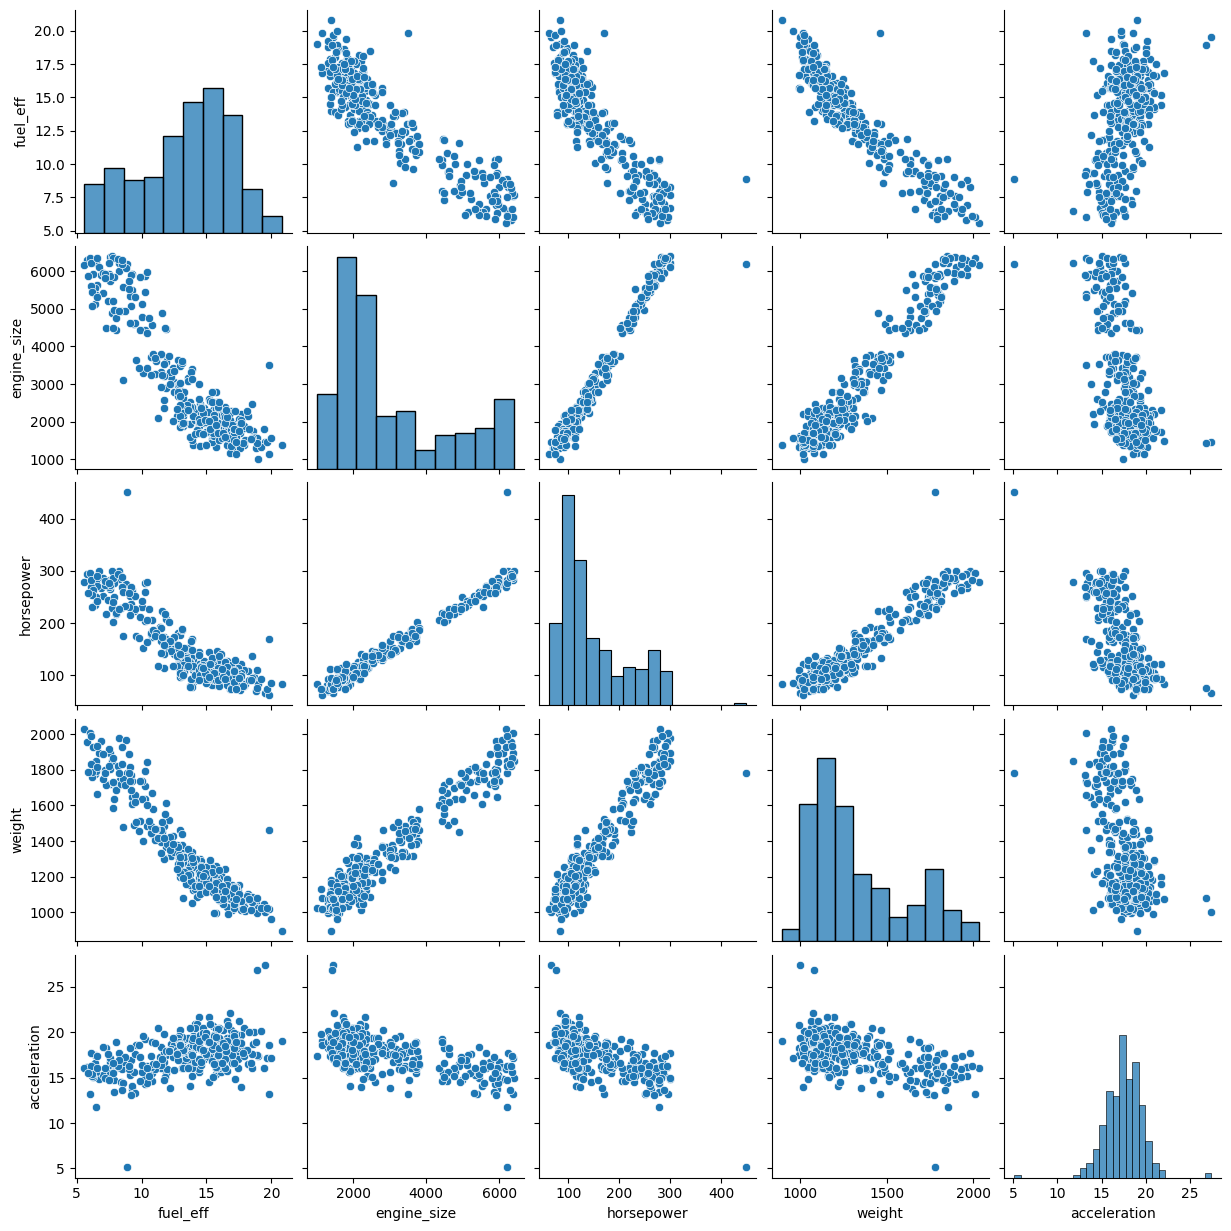

In [ ]:
sns.pairplot(df[["fuel_eff", "engine_size", "horsepower",
                 "weight", "acceleration"]])

plt.show()

## **(a) Identifying the strong positive relationships & the tightest band of them :**

The pairs of attributes that show a strongest positive relationships are  **"engine_size and horsepower"**, **"horsepower and weight"** and **"engine_size and weight"**.

**The engine_size and horsepower** pair forms **the tightest band** of points.

## **(b) Describe the relations between fuel_eff and the other attributes :**

As engine_size, horsepower, and weight **increase** , fuel_eff **decreases**.They have negative relationship with fuel_eff.

The relationships are **not** perfectly linear.

The **Weight** appears to have **the strongest relationship** with **fuel_eff** among the three attributes.

## **(c) Identifying the weakest relationship and describe the appearance of its points :**

**The weakest relationship** is between **fuel_eff and acceleration**.

The points are widely scattered and show unclear pattern.

## **(d) Identifying the vehicle that stands apart in the fuel_eff vs engine_size plot & Give its coordinates and state whether it is a data-entry error or a natural outlier :**


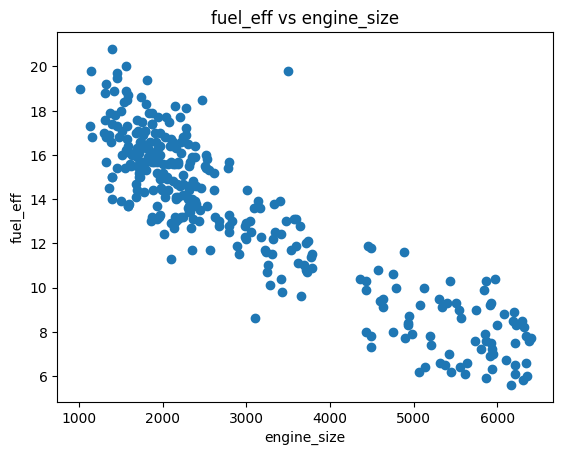

The coordinates of the vehicle that stands apart are:


,car_name,engine_size,fuel_eff
17,toyota highlander hybrid,3500,19.8


In [ ]:
plt.scatter(df["engine_size"], df["fuel_eff"])
plt.xlabel("engine_size")
plt.ylabel("fuel_eff")
plt.title("fuel_eff vs engine_size")
plt.show()

print("========================================================")
print("The coordinates of the vehicle that stands apart are:")
print("========================================================")

df.loc[
    (df["engine_size"] > 3000) & (df["fuel_eff"] > 15),
    ["car_name", "engine_size", "fuel_eff"]
]

 The vehicle that clearly stands apart from all the other vehicles is **"Toyota Highlander Hybrid"**.

 It’s coordinates **(engine_size = 3500, fuel_eff = 19.8)**.

 It appears to be a natural outlier rather than an error, The plot alone is not enough to confirm whether it is an error or not.

## **(e) Identifying the vehicle that is far from the others in panels involving horsepower and acceleration. Where it is also identified? :**

According to the Outliers of accelaration that were identified before **(in Question 2_Part A(b) )** ,

**"Chevrolet Corvette"** has **horsepower = 450** and **acceleration = 5.1** , Which makes it appear to be far from the others in the scatter plot panels.

It was also identified before as an outlier in the acceleration box plot **(in Question 2_Part A(a) )**.

## **(f)  Identifying potentially redundant attributes and choosing one to predict fuel_eff :**

The attributes **engine_size, horsepower, and weight** (may be redundant); As they have strong positive relationships with each other.

If we keep only one attribute **to predict fuel_eff**, We would choose **weight** ; As it has the strongest negative relationship with **fuel_eff** among the three attributes.


---

---

---


# ***Question 4 _ Two-way Cross-tabulation***

A marketing report claims that big engines (more than 4 cylinders) are essentially a North American phenomenon, while European and Asian manufacturers concentrate on small engines. We treat cylinders and origin as categorical attributes (1 = North America, 2 = Europe, 3 = Asia) and use a two-way cross-tabulation to evaluate this claim.


In [ ]:
# Two-way cross-tabulation (counts)
region_names = {1: "North America", 2: "Europe", 3: "Asia"}

crosstab = pd.crosstab(df["cylinders"], df["origin"].map(region_names), margins=True, margins_name="Total")
crosstab = crosstab[["North America", "Europe", "Asia", "Total"]]

display(crosstab)

origin,North America,Europe,Asia,Total
cylinders,,,,
3,0,0,4,4
4,60,49,61,170
5,0,8,0,8
6,55,2,6,63
8,75,0,0,75
Total,190,59,71,320


## **(a) Cylinder counts found in only one region :**

In [ ]:
# Count the number of regions in which each cylinder count appears
table = crosstab.drop(index="Total", columns="Total")

for cyl, row in table.iterrows():
    regions = row[row > 0].index.tolist()
    if len(regions) == 1:
        print(f"{cyl} cylinders  ==>  found only in {regions[0]}  ({row[regions[0]]} vehicles)")

3 cylinders  ==>  found only in Asia  (4 vehicles)
5 cylinders  ==>  found only in Europe  (8 vehicles)
8 cylinders  ==>  found only in North America  (75 vehicles)


Three cylinder counts appear in a single region only:

3 cylinders : found only in Asia (4 vehicles).
5 cylinders : found only in Europe (8 vehicles).
8 cylinders : found only in North America (75 vehicles).
4 and 6 cylinders appear in all three regions.

## **(b) The most common (mode) number of cylinders in each region :**

In [ ]:
# Mode of cylinders in each region
for region in ["North America", "Europe", "Asia"]:
    counts = table[region]
    print(f"{region}: mode = {counts.idxmax()} cylinders  ({counts.max()} vehicles)")

North America: mode = 8 cylinders  (75 vehicles)
Europe: mode = 4 cylinders  (49 vehicles)
Asia: mode = 4 cylinders  (61 vehicles)


North America : the mode is 8 cylinders (75 vehicles), slightly ahead of 4 cylinders (60 vehicles).

Europe : the mode is 4 cylinders (49 vehicles).

Asia : the mode is 4 cylinders (61 vehicles).

North America is the only region whose most common engine is a big engine.


## **(c) Vehicles with more than 4 cylinders in each region :**

In [ ]:
# Vehicles with more than 4 cylinders per region
big = df[df["cylinders"] > 4]

summary = pd.DataFrame({
    "Total vehicles": df["origin"].map(region_names).value_counts(),
    "Vehicles with > 4 cylinders": big["origin"].map(region_names).value_counts()
}).loc[["North America", "Europe", "Asia"]]

summary["% of region"] = (summary["Vehicles with > 4 cylinders"] / summary["Total vehicles"] * 100).round(2)

display(summary)

na_share = summary.loc["North America", "Vehicles with > 4 cylinders"] / len(big) * 100
print("Total vehicles with more than 4 cylinders:", len(big))
print("Share of North America among them:", round(na_share, 2), "%")

,Total vehicles,Vehicles with > 4 cylinders,% of region
origin,,,
North America,190,130,68.42
Europe,59,10,16.95
Asia,71,6,8.45


Total vehicles with more than 4 cylinders: 146
Share of North America among them: 89.04 %


North America : 130 vehicles out of 190, which is 68.42 % of the region.

Europe : 10 vehicles out of 59, which is 16.95 % of the region.

Asia : 6 vehicles out of 71, which is 8.45 % of the region.

There are 146 vehicles with more than 4 cylinders in total, and North America contributes 130 of them, which is 89.04 %.

## **(d) Does the data support the marketing claim ? :**

Yes, the data largely supports the claim. Most big-engine vehicles (89.04 %) come from North America, and North America is the only region whose mode is 8 cylinders. In contrast, 83.05 % of European vehicles and 91.55 % of Asian vehicles have 4 cylinders or fewer.

The claim is not perfectly accurate, however: Europe has 8 vehicles with 5 cylinders, and some European and Asian vehicles have 6 cylinders (2 and 6 vehicles). Also, 31.58 % of North American vehicles still have 4 cylinders or fewer.

A limitation : the data set is unbalanced and is only a sample. North America has 190 of the 320 vehicles, compared with 59 for Europe and 71 for Asia, and each row is a vehicle model, not a sales figure. So the data describes the models in this sample, not the real market, and it cannot prove a general claim about all manufacturers.

## **(e) Link with the origin box plot (Question 2 _ Part C) :**

The cross-tabulation shows that North America (origin = 1) has 190 vehicles, which is 59.4 % of all vehicles. This is why Q1 = Q2 = 1 in the origin box plot: the first 190 sorted values are all 1, so the first quartile (position 80) and the median (position 160) both fall inside this group. This puts the median band on the lower edge of the box and gives a lower whisker of zero length. Europe and Asia are much smaller groups, so Q3 = 2 and the upper whisker reaches 3.
